# Iris Classification with k-Nearest Neighbors
Author: Manuel Eugenio Morocho Cayamcela, PhD

## Introduction
Use supervised learning to classify 150 Iris flowers into three species from four measurements: sepal length, sepal width, petal length, and petal width (in centimeters). This lesson covers loading data, exploration, preprocessing, training a k-nearest neighbors (k-NN) classifier, saving the model, and evaluating predictions.

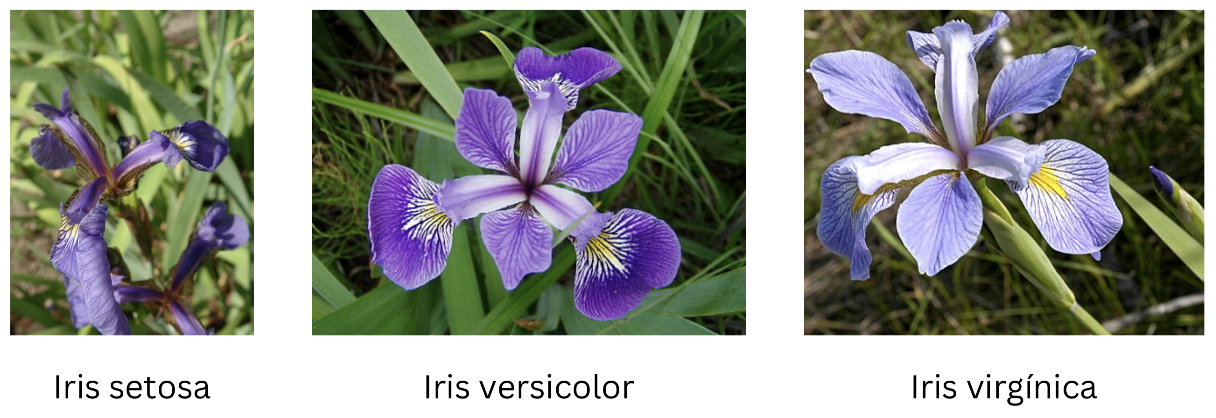

## Setup
If needed, install the packages once with `%pip install pandas matplotlib seaborn scikit-learn joblib`. Restart the kernel after installation if requested.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

## Load the Iris dataset
Read the Iris CSV directly from GitHub using pandas. An internet connection is required.

In [2]:
github_url = "https://raw.githubusercontent.com/eugeniomorocho/ArtificialIntelligence/main/Datasets/iris.csv"
iris = pd.read_csv(github_url)

## Explore and prepare the data
Run each cell separately and inspect its output before continuing.

Preview the first five records.

In [3]:
iris.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


Inspect column types and non-null counts to identify missing values.

In [4]:
iris.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


Summarize the numeric columns.

In [5]:
iris.describe()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


Count the examples of each species.

In [6]:
iris["Species"].value_counts()

Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

Remove `Id`: it identifies records rather than measuring flowers.

In [7]:
iris = iris.drop(columns="Id")

## Visualize the measurements
Compare sepal and petal measurements by species. Setosa is particularly distinct in petal measurements; versicolor and virginica overlap more. These plots help assess whether the measurements can separate the classes.

### Sepal measurements

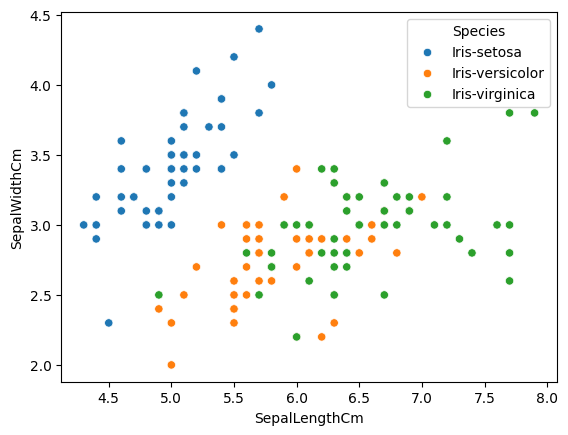

In [8]:
sns.scatterplot(data=iris, x="SepalLengthCm", y="SepalWidthCm", hue="Species")
plt.show()

### Petal measurements

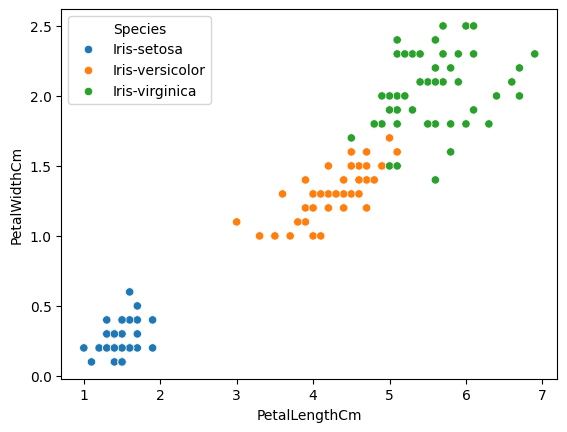

In [9]:
sns.scatterplot(data=iris, x="PetalLengthCm", y="PetalWidthCm", hue="Species")
plt.show()

The pair plot compares every pair of measurements. Histograms on the diagonal show each feature's distribution.

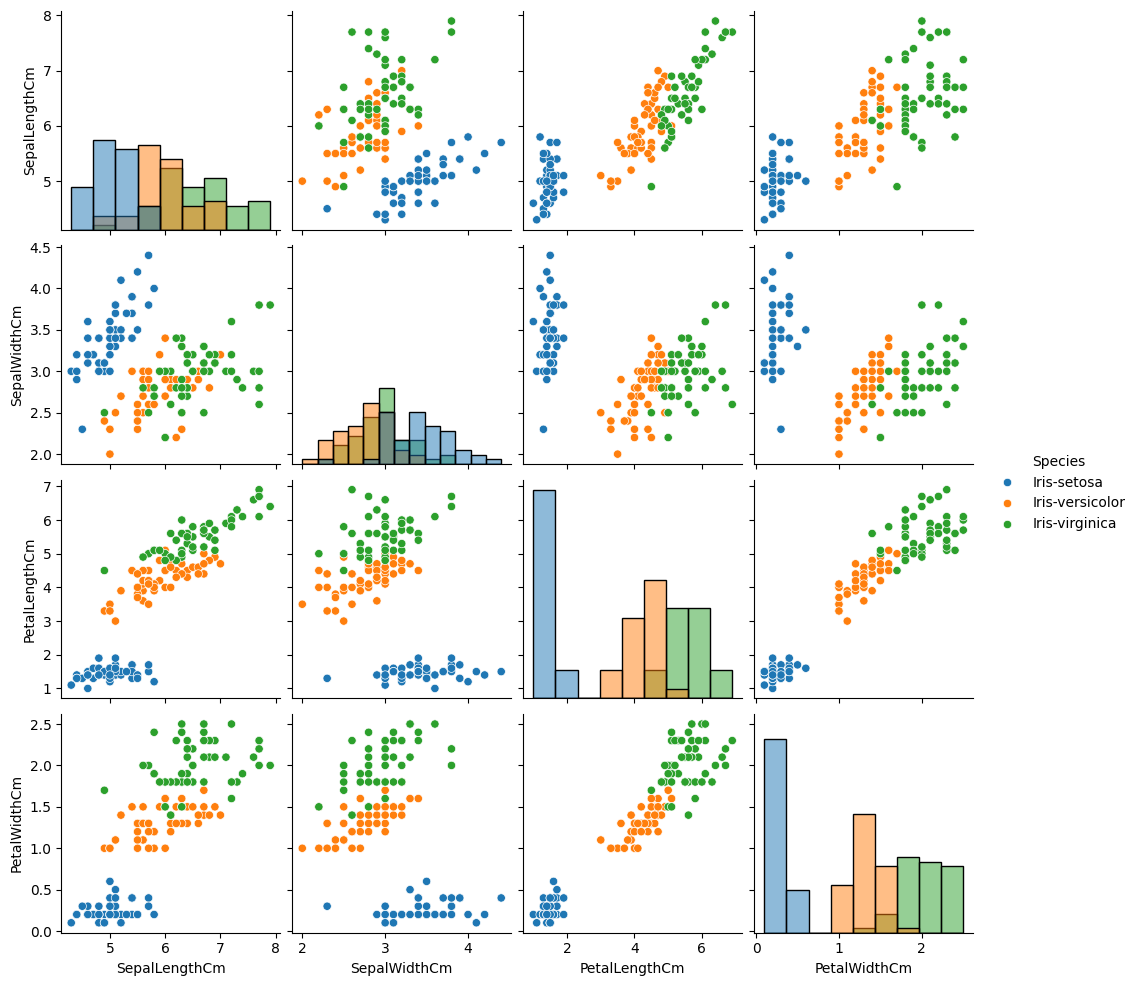

In [10]:
sns.pairplot(iris, hue="Species", diag_kind="hist")
plt.show()

## Prepare training and test sets
Separate the four predictors (`X`) from the species label (`y`). Reserve 20% of the data for testing. Stratification preserves class proportions, and a fixed random seed makes the split reproducible. Keep the test set out of model fitting.

In [11]:
# Isolate features
X = iris.drop(columns="Species")

# Isolate target variable
y = iris["Species"]

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

## Train the k-NN classifier
With `n_neighbors=5`, the classifier predicts a flower's species from the majority class among its five nearest training examples. Fit the model on the training set only.

In [12]:
from sklearn.neighbors import KNeighborsClassifier

classifier = KNeighborsClassifier(n_neighbors=5)
classifier.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](3,)","['Iris-setosa','Iris-versicolor','Iris-virginica']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


## Evaluate on unseen data
Predict the species of the held-out examples.

In [13]:
predictions = classifier.predict(X_test)

### Accuracy
Accuracy is the fraction of correctly classified test examples.

In [14]:
print(f"Test accuracy: {accuracy_score(y_test, predictions):.3f}")

Test accuracy: 1.000


### Classification report
The report summarizes each species:

- **Precision:** TP / (TP + FP), the fraction of predictions for that species that are correct.
- **Recall:** TP / (TP + FN), the fraction of actual flowers of that species correctly identified.
- **F1-score:** the harmonic mean of precision and recall.
- **Support:** the number of true examples of that species in the test set.

Interpret the results generated below; scores can change with the split and model settings.

In [15]:
print(classification_report(y_test, predictions, zero_division=0))

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      1.00      1.00        10
 Iris-virginica       1.00      1.00      1.00        10

       accuracy                           1.00        30
      macro avg       1.00      1.00      1.00        30
   weighted avg       1.00      1.00      1.00        30



### Confusion matrix
Rows show actual classes and columns show predicted classes. Diagonal entries are correct predictions.

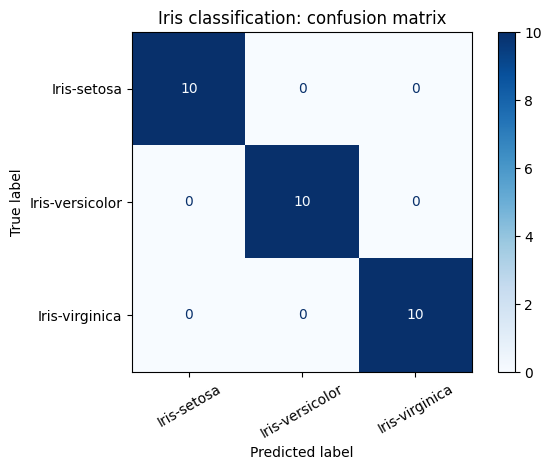

In [16]:
ConfusionMatrixDisplay.from_predictions(
    y_test, predictions, labels=classifier.classes_, cmap="Blues"
)
plt.title("Iris classification: confusion matrix")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Save and reload the trained model
Save the fitted classifier for reuse without retraining. Only load model files you trust. The file is written to the current working directory.

In [17]:
import joblib

model_path = Path("knn_model.pkl")
joblib.dump(classifier, model_path)

['knn_model.pkl']

In [18]:
loaded_classifier = joblib.load(model_path)
loaded_classifier.predict(X_test.head())

array(['Iris-setosa', 'Iris-virginica', 'Iris-versicolor',
       'Iris-versicolor', 'Iris-setosa'], dtype=object)

## Activity: Data Preprocessing and Customer Classification with k-NN
### Objective
Explore a classification dataset, train k-NN, and select a suitable value of `k`. Work individually or in a group, share the work fairly, and justify your decisions.

### Where to find datasets
For this short activity, choose a small tabular dataset with a clearly documented categorical target. Prefer CSV files and numeric predictors so that data preparation remains manageable.

- [UCI Machine Learning Repository](https://archive.ics.uci.edu/): a useful starting point for classification datasets.
- [Kaggle Datasets](https://www.kaggle.com/datasets): browse datasets and select one with a documented target and downloadable tabular files. Check access requirements before choosing it.
- [Awesome Public Datasets on GitHub](https://github.com/awesomedata/awesome-public-datasets): a topic-based directory linking to datasets; check the original source for files and documentation.
- [Ecuador Open Data Portal — CSV datasets](https://www.datosabiertos.gob.ec/dataset/?res_format=CSV): explore Ecuadorian public data available in CSV format.
- [INEC Open Data Bank](https://aplicaciones3.ecuadorencifras.gob.ec/BIINEC-war/index.xhtml): find Ecuadorian statistical information and consult the accompanying documentation.
- [U.S. Government Open Data](https://data.gov/): search public datasets by topic or organization.

Government portals are useful for local or applied topics, but their tables may require more cleaning and may not have a ready-made classification target. Verify the target column and download format before committing to a dataset.

### Instructions
1. **Find and explore a dataset (10 minutes).** Load a classification dataset, inspect its structure, and clean or transform it as needed.

#### Dataset source
**Breast Cancer Wisconsin (Diagnostic)**, UCI Machine Learning Repository (CC BY 4.0). https://doi.org/10.24432/C5DW2B

569 breast masses described by 30 numeric features of cell nuclei, computed from fine needle aspirate (FNA) images. Target: `diagnosis`, M (malignant) or B (benign).

#### Load the data
Read `wdbc.data` (no header row) directly from the `.zip`. Column names follow `wdbc.names`: 10 measurements, each given as mean, standard error (`se`) and worst value.

In [19]:
# Import the dataset
import zipfile

zip_path = Path("datasets/breast+cancer+wisconsin+diagnostic.zip")

features = ["radius", "texture", "perimeter", "area", "smoothness",
            "compactness", "concavity", "concave_points", "symmetry", "fractal_dimension"]
columns = ["id", "diagnosis"] + [f"{f}_{s}" for s in ("mean", "se", "worst") for f in features]

with zipfile.ZipFile(zip_path) as zf:
    print(zf.namelist())
    with zf.open("wdbc.data") as f:
        wdbc = pd.read_csv(f, header=None, names=columns)

print(wdbc.shape)
print(wdbc["diagnosis"].value_counts())

['wdbc.data', 'wdbc.names']
(569, 32)
diagnosis
B    357
M    212
Name: count, dtype: int64


#### Explore and clean the data
Inspect column types and non-null counts.

In [20]:
wdbc.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave_points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

Check for missing values and duplicates.

In [21]:
print("Missing values:", wdbc.isna().sum().sum())
print("Duplicate rows:", wdbc.duplicated().sum())
print("Duplicate ids:", wdbc["id"].duplicated().sum())

Missing values: 0
Duplicate rows: 0
Duplicate ids: 0


Check whether the zeros in the concavity features could be missing values.

In [22]:
print((wdbc[["concavity_mean", "concave_points_mean"]] == 0).sum())
print("Both zero:", ((wdbc["concavity_mean"] == 0) & (wdbc["concave_points_mean"] == 0)).sum())

concavity_mean         13
concave_points_mean    13
dtype: int64
Both zero: 13


The same 13 samples are zero in both features (nuclei without concave regions). These are valid values and are kept.

Remove `id`: it identifies samples rather than measuring them.

In [23]:
wdbc = wdbc.drop(columns="id")

Summarize the feature scales, sorted by standard deviation.

In [24]:
wdbc.describe().T[["mean", "std", "min", "max"]].sort_values("std", ascending=False)

,mean,std,min,max
area_worst,880.583128,569.356993,185.200000,4254.00000
area_mean,654.889104,351.914129,143.500000,2501.00000
area_se,40.337079,45.491006,6.802000,542.20000
perimeter_worst,107.261213,33.602542,50.410000,251.20000
perimeter_mean,91.969033,24.298981,43.790000,188.50000
texture_worst,25.677223,6.146258,12.020000,49.54000
radius_worst,16.269190,4.833242,7.930000,36.04000
texture_mean,19.289649,4.301036,9.710000,39.28000
radius_mean,14.127292,3.524049,6.981000,28.11000
perimeter_se,2.866059,2.021855,0.757000,21.98000


Scales differ by several orders of magnitude, so the features are standardized before training k-NN.

Count the examples of each class.

In [25]:
wdbc["diagnosis"].value_counts(normalize=True).round(3)

diagnosis
B    0.627
M    0.373
Name: proportion, dtype: float64

#### Visualize the measurements
Pair plot of four representative features.

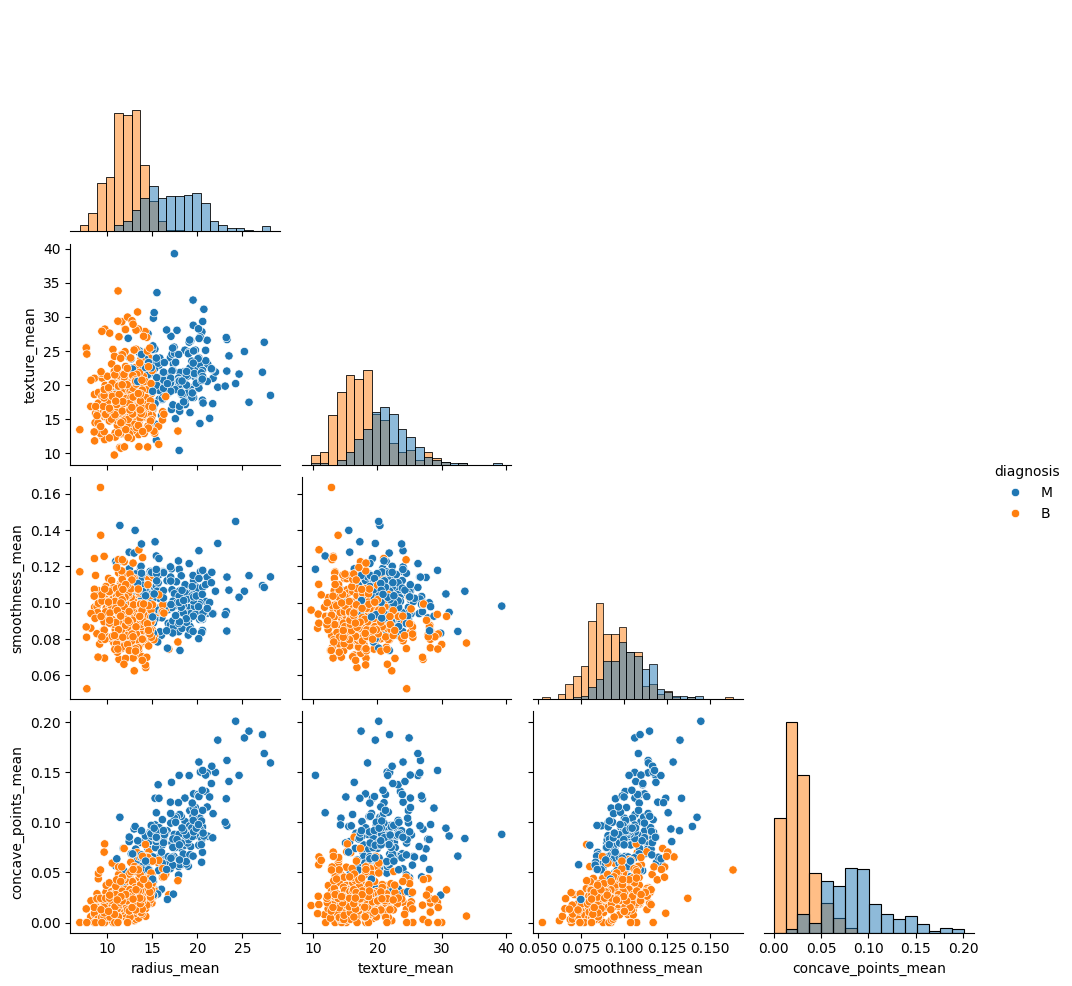

In [26]:
subset = ["radius_mean", "texture_mean", "smoothness_mean", "concave_points_mean", "diagnosis"]
sns.pairplot(wdbc[subset], hue="diagnosis", diag_kind="hist", corner=True)
plt.show()

Correlation between features.

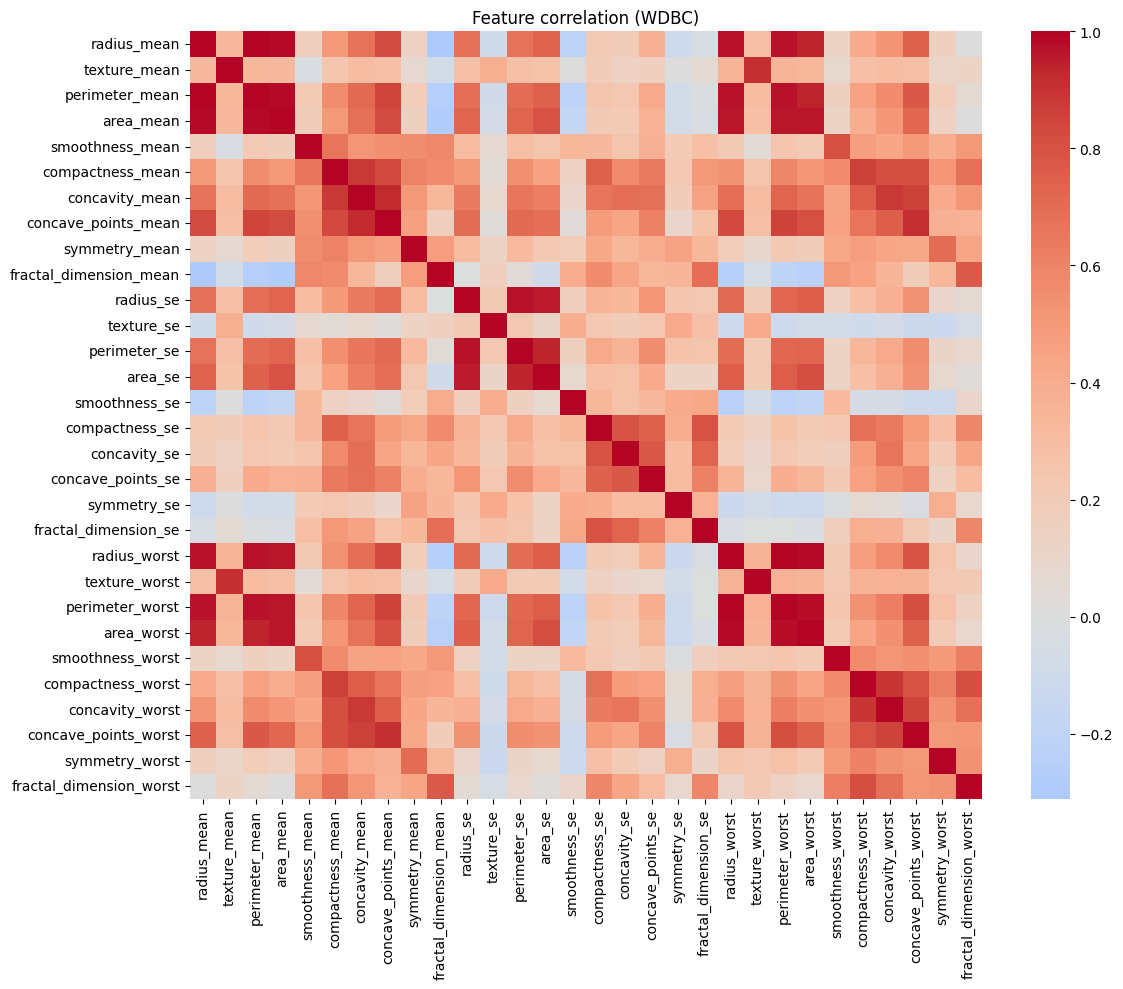

In [27]:
corr = wdbc.drop(columns="diagnosis").corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, xticklabels=True, yticklabels=True)
plt.title("Feature correlation (WDBC)")
plt.tight_layout()
plt.show()

2. **Classify with k-NN (20 minutes).** Split the data into training and test sets, train the classifier, and report accuracy. Select `k` using only training data (for example, cross-validation), then evaluate the chosen model on the test set. Predict a new example outside both sets. Complete the random forest comparison in the companion notebook.

#### Prepare training and test sets
Stratified 80/20 split with a fixed seed. The test set is not used until `k` is chosen.

In [28]:
# Isolate features and target
X = wdbc.drop(columns="diagnosis")
y = wdbc["diagnosis"]

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("Train:", X_train.shape, "Test:", X_test.shape)
print(pd.concat([y_train.value_counts(normalize=True), y_test.value_counts(normalize=True)],
                axis=1, keys=["train", "test"]).round(3))

Train: (455, 30) Test: (114, 30)
           train   test
diagnosis              
B          0.626  0.632
M          0.374  0.368


#### Select `k` with cross-validation
10-fold stratified cross-validation on the training set, for odd `k` from 1 to 31. Standardization is applied inside a pipeline, and unscaled models are included for comparison.

In [29]:
# Select the best k value for the k-NN classifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
k_values = list(range(1, 32, 2))

scaled_mean, scaled_std, raw_mean = [], [], []
for k in k_values:
    scaled_model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    raw_model = KNeighborsClassifier(n_neighbors=k)

    scores = cross_val_score(scaled_model, X_train, y_train, cv=cv)
    scaled_mean.append(scores.mean())
    scaled_std.append(scores.std())
    raw_mean.append(cross_val_score(raw_model, X_train, y_train, cv=cv).mean())

cv_results = pd.DataFrame({
    "k": k_values,
    "CV accuracy (scaled)": scaled_mean,
    "Std across folds": scaled_std,
    "CV accuracy (raw)": raw_mean,
})
cv_results.round(3)

,k,CV accuracy (scaled),Std across folds,CV accuracy (raw)
0,1,0.956,0.037,0.930
1,3,0.971,0.031,0.932
2,5,0.963,0.040,0.930
3,7,0.967,0.035,0.934
4,9,0.965,0.035,0.936
5,11,0.963,0.033,0.930
6,13,0.958,0.035,0.925
7,15,0.960,0.035,0.925
8,17,0.963,0.037,0.925
9,19,0.963,0.037,0.923


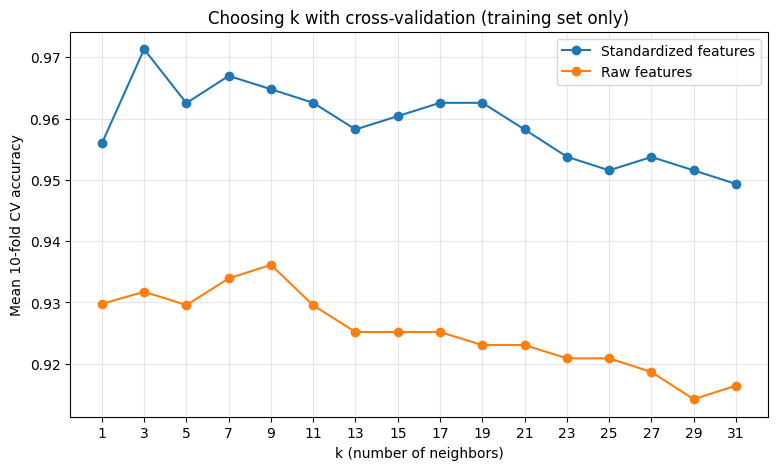

In [30]:
plt.figure(figsize=(9, 5))
plt.plot(k_values, scaled_mean, marker="o", label="Standardized features")
plt.plot(k_values, raw_mean, marker="o", label="Raw features")
plt.xlabel("k (number of neighbors)")
plt.ylabel("Mean 10-fold CV accuracy")
plt.title("Choosing k with cross-validation (training set only)")
plt.xticks(k_values)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [31]:
best_row = cv_results.loc[cv_results["CV accuracy (scaled)"].idxmax()]
best_k = int(best_row["k"])
print(f"Best k = {best_k} (mean CV accuracy = {best_row['CV accuracy (scaled)']:.3f})")

Best k = 3 (mean CV accuracy = 0.971)


#### Justification of the chosen `k`
- Standardization improves CV accuracy for every `k` (≈0.95–0.97 vs 0.91–0.94 without scaling).
- `k = 1` (0.956) overfits: each prediction depends on a single neighbor.
- For `k ≥ 21` accuracy tends to decrease (0.949 at `k = 31`): neighborhoods become too large and the model underfits.
- `k = 3` has the highest CV accuracy (0.971). Values from 3 to 9 differ by less than 1 point, which is smaller than the variation across folds (std ≈ 0.03). The choice uses training data only.

#### Evaluate on unseen data
Train the pipeline with `best_k` on the full training set and evaluate it once on the test set.

In [32]:
# Fit a k-NN classifier to the training data
final_model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k))
final_model.fit(X_train, y_train)

test_predictions = final_model.predict(X_test)
print(f"Test accuracy: {accuracy_score(y_test, test_predictions):.3f}")

Test accuracy: 0.939


In [33]:
print(classification_report(y_test, test_predictions, digits=3))

              precision    recall  f1-score   support

           B      0.922     0.986     0.953        72
           M      0.973     0.857     0.911        42

    accuracy                          0.939       114
   macro avg      0.948     0.922     0.932       114
weighted avg      0.941     0.939     0.938       114



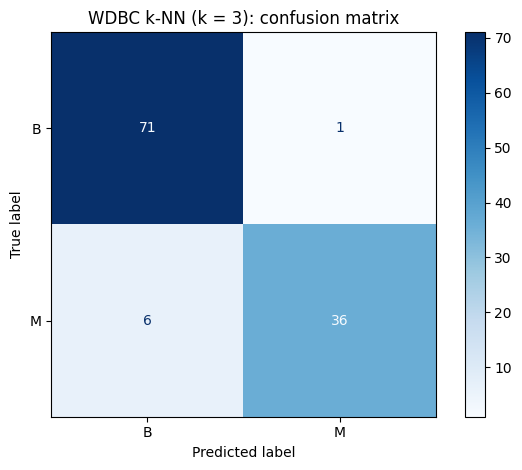

In [34]:
ConfusionMatrixDisplay.from_predictions(
    y_test, test_predictions, labels=["B", "M"], cmap="Blues"
)
plt.title(f"WDBC k-NN (k = {best_k}): confusion matrix")
plt.tight_layout()
plt.show()

#### Predict new examples
Two hypothetical cases outside both sets, built from the median benign and the median malignant training profiles.

In [35]:
new_examples = X_train.groupby(y_train).median()
new_examples.index = ["New case 1 (median benign profile)", "New case 2 (median malignant profile)"]

result = pd.DataFrame(final_model.predict_proba(new_examples),
                      index=new_examples.index, columns=final_model.classes_)
result["prediction"] = final_model.predict(new_examples)
result

,B,M,prediction
New case 1 (median benign profile),1.0,0.0,B
New case 2 (median malignant profile),0.0,1.0,M


3. **Present the dataset and process (30 minutes).** Explain decisions and results, and discuss possible improvements.


Write a brief explanation of the dataset, preprocessing steps, and model evaluation...

#### Datos
El conjunto de datos Breast Cancer Wisconsin (Diagnostic) de UCI contiene 569 muestras de masas mamarias, cada una descrita mediante 30 características numéricas de los núcleos celulares medidas a partir de imágenes obtenidas por aspiración con aguja fina (FNA). La variable objetivo `diagnosis` tiene dos clases: benigno (B, 62.7 %) y maligno (M, 37.3 %). Cumple con los criterios de la actividad: datos tabulares, variables predictoras numéricas y una variable objetivo categórica documentada.

#### Preprocesamiento
- **Carga:** se leyó el archivo `wdbc.data` desde el archivo `.zip`; los nombres de las columnas se obtuvieron de `wdbc.names`.
- **Calidad de los datos:** no se encontraron valores faltantes ni registros duplicados. Los 13 valores iguales a cero en las características de concavidad corresponden a mediciones válidas, por lo que no se eliminó ninguna fila.
- **Limpieza:** se eliminó la columna `id` porque identifica las muestras, pero no describe sus características.
- **Escalado:** las escalas de las características difieren en varios órdenes de magnitud (desviación estándar de `area_worst` ≈ 569 frente a `fractal_dimension_se` ≈ 0.003). Como k-NN utiliza distancias, se estandarizaron las características. El escalador está integrado en un pipeline, de modo que sus parámetros se ajustan únicamente con los datos de entrenamiento.
- **División de datos:** se realizó una división estratificada del 80/20 (455 muestras de entrenamiento y 114 de prueba), conservando las proporciones de las clases en ambos conjuntos.

#### Análisis exploratorio
- Las características `radius_mean` y `concave_points_mean` permiten distinguir adecuadamente las clases: los núcleos de las muestras malignas presentan mayor tamaño y más puntos cóncavos. En cambio, `smoothness_mean` presenta un solapamiento considerable entre ambas clases.
- El radio, el perímetro y el área están correlacionados casi perfectamente, por lo que la información relacionada con el tamaño se representa varias veces en el cálculo de las distancias.

#### Evaluación del modelo
- **Modelo seleccionado:** k-NN con características estandarizadas y `k = 3`, seleccionado mediante validación cruzada de 10 particiones sobre el conjunto de entrenamiento (exactitud en validación cruzada de 0.971).
- **Exactitud (accuracy):** 0.939 en el conjunto de prueba, considerablemente superior al 0.632 obtenido al predecir siempre la clase mayoritaria (B).
- **Matriz de confusión:** se clasificaron correctamente 71 de 72 tumores benignos y 36 de 42 tumores malignos. Se obtuvo 1 falso positivo y 6 falsos negativos.
- **Precisión (M) = 0.973:** cuando el modelo predice que un tumor es maligno, casi siempre acierta.
- **Sensibilidad (recall) (M) = 0.857:** el modelo no detecta aproximadamente el 14 % de los tumores malignos. En un contexto de diagnóstico, este es el error más grave.
- **Validación cruzada frente a prueba:** la exactitud en el conjunto de prueba (0.939) es inferior a la obtenida mediante validación cruzada (0.971). Con 114 muestras de prueba, cada error modifica la exactitud en aproximadamente 0.9 puntos porcentuales, por lo que la diferencia equivale a unos 4 errores y se encuentra dentro de la variabilidad observada entre las particiones (desviación estándar ≈ 0.03).
- **Nuevos ejemplos:** ambos casos hipotéticos se clasificaron según lo esperado, con concordancia entre los 3 vecinos más cercanos.

#### Posibles mejoras
- **Detectar más tumores malignos:** seleccionar `k` utilizando la sensibilidad (recall) o la puntuación F1 de la clase M en lugar de la exactitud, o predecir M cuando al menos 1 de los 3 vecinos sea maligno (utilizando `predict_proba`).
- **Reducir características redundantes:** eliminar características altamente correlacionadas o aplicar técnicas de selección de características para evitar que el tamaño domine el cálculo de las distancias.
- **Vecinos ponderados:** utilizar `weights="distance"` para que los vecinos más cercanos tengan mayor influencia en la predicción.
- **Comparar modelos:** completar la comparación con el modelo Random Forest en el notebook complementario.

### Assessment
- Dataset source: 10%.
- Training/test split: 20%.
- Justification of the chosen `k`: 40%.
- Classification metrics: 30%.

### Deliverable
Submit the Jupyter notebook results as a PDF.